In [1]:
import sys
from pathlib import Path

# games.py repo kökünde; notebook nereden çalışırsa çalışsın kökü bul
ROOT = Path.cwd() if (Path.cwd() / "games.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from games import asset_paths, half_video_blocks
from kloppy import metrica

paths = asset_paths()
dataset = metrica.load_tracking_epts(meta_data=paths["atd_meta"], raw_data=paths["atd_raw"])
df = dataset.to_df()

print("Satır:", len(df), "| kolon:", df.shape[1])
print("frame_id aralığı:", df["frame_id"].min(), "-", df["frame_id"].max())
print("Puanlanan yarılar:", half_video_blocks("BAR-ATH"))
for t in dataset.metadata.teams:
    print(t.name, "| iz sayısı:", len(t.players))

Satır: 199319 | kolon: 193
frame_id aralığı: 1 - 199319
Puanlanan yarılar: [(1, 11185, 90651), (2, 110808, 190197)]
Barcelona | iz sayısı: 24
Atletic Club | iz sayısı: 22


In [2]:
import numpy as np
import pandas as pd

df["video_frame"] = df["frame_id"] - 1
graded = np.zeros(len(df), dtype=bool)
for _, a, b in half_video_blocks("BAR-ATH"):
    graded |= df["video_frame"].between(a, b).to_numpy()

meta_cols = [c for c in df.columns if not c.split("_")[0].isdigit()]
print("Oyuncu dışı kolonlar:", meta_cols)
ekler = pd.Series([c.split("_")[-1] for c in df.columns if c.split("_")[0].isdigit()]).value_counts()
print("Oyuncu kolon ekleri:", ekler.to_dict())

for c in ["ball_state", "ball_owning_team_id"]:
    if c in df.columns:
        print(f"{c}:", df[c].value_counts(dropna=False).head().to_dict())

print("\nPuanlanan kare:", graded.sum())
print("Top görünür (puanlanan karelerde):", round(df.loc[graded, "ball_x"].notna().mean(), 3))

teams = dataset.metadata.teams
ids = {t.name: [p.player_id for p in t.players] for t in teams}
for name, pid in ids.items():
    n = df.loc[graded, [f"{i}_x" for i in pid]].notna().sum(axis=1)
    print(f"{name}: ortalama {n.mean():.1f} oyuncu görünür (puanlanan karelerde)")

Oyuncu dışı kolonlar: ['period_id', 'timestamp', 'frame_id', 'ball_state', 'ball_owning_team_id', 'ball_x', 'ball_y', 'ball_z', 'ball_speed', 'video_frame']
Oyuncu kolon ekleri: {'x': 46, 'y': 46, 'd': 46, 's': 46}
ball_state: {None: 199319}
ball_owning_team_id: {None: 199319}

Puanlanan kare: 158857
Top görünür (puanlanan karelerde): 0.593
Barcelona: ortalama 10.2 oyuncu görünür (puanlanan karelerde)
Atletic Club: ortalama 10.3 oyuncu görünür (puanlanan karelerde)


In [3]:
import warnings

# Önbellek: sonraki oturumlarda hızlı yüklemek için (data/ altında, git'e girmez)
df.to_pickle(ROOT / "data" / "cache_atd_tactical.pkl")

L, W = 105.3, 68.0                       # saha ölçüleri (m), games.py'deki değerler
names = [t.name for t in teams]
assert names[0] == "Barcelona"           # ev sahibi = H
bx = df["ball_x"].to_numpy() * L
by = df["ball_y"].to_numpy() * W

def min_dist(pids):
    X = df[[f"{i}_x" for i in pids]].to_numpy() * L
    Y = df[[f"{i}_y" for i in pids]].to_numpy() * W
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmin(np.sqrt((X - bx[:, None])**2 + (Y - by[:, None])**2), axis=1)

d_H = min_dist(ids[names[0]])
d_A = min_dist(ids[names[1]])
d_min = np.fmin(d_H, d_A)

ok = graded & ~np.isnan(bx)
print("Top görünürken topa en yakın oyuncunun mesafesi (m), puanlanan kareler:")
print(pd.Series(d_min[ok]).describe(percentiles=[.1, .25, .5, .75, .9]).round(2))
print("\n0,3 m içinde oyuncu olan karelerin oranı:", round((d_min[ok] < 0.3).mean(), 3))
print("1,0 m içinde:", round((d_min[ok] < 1.0).mean(), 3), "| 2,0 m içinde:", round((d_min[ok] < 2.0).mean(), 3))

Top görünürken topa en yakın oyuncunun mesafesi (m), puanlanan kareler:
count    94214.00
mean         3.11
std          3.86
min          0.00
10%          0.44
25%          0.89
50%          1.91
75%          4.06
90%          7.02
max         86.90
dtype: float64

0,3 m içinde oyuncu olan karelerin oranı: 0.057
1,0 m içinde: 0.285 | 2,0 m içinde: 0.515


In [4]:
# --- Sahiplik v1: yapışkan sahiplik + onay kuralı (ölü top henüz yok) ---
R = 1.5   # m: bu mesafedeki oyuncu topa temas ediyor sayılır
K = 10    # kare: sahiplik değişimi için aynı takımın kesintisiz temas süresi (0,4 sn)

assert (df["video_frame"].to_numpy() == np.arange(len(df))).all()   # satır i = video karesi i

cand = np.where(d_H < d_A, "H", "A")
cand = np.where(np.fmin(d_H, d_A) < R, cand, "")    # temas yoksa boş

def sticky_confirmed(c, K):
    out = np.full(len(c), None, dtype=object)
    cur, run_team, run_start = None, "", 0
    for i, t in enumerate(c):
        if t != run_team:
            run_team, run_start = t, i
        if t and t != cur and i - run_start + 1 >= K:
            cur = t
            out[run_start:i] = cur     # geçişi temasın başladığı kareye geri yaz
        out[i] = cur
    return out

pred = np.full(len(df), "X", dtype=object)
for _, a, b in half_video_blocks("BAR-ATH"):
    sl = slice(a, b + 1)
    seg = pd.Series(sticky_confirmed(cand[sl], K)).bfill().fillna("X")
    pred[sl] = seg.to_numpy()

# Gönderim formatını organizatör baseline'ından al
base = pd.read_csv(ROOT / "evaluation" / "results" / "baseline_smooth50.csv")
assert len(base) == len(df) and len(base.columns) == 2
sub = pd.DataFrame({base.columns[0]: np.arange(len(df)), base.columns[1]: pred})
out_path = ROOT / "evaluation" / "results" / f"v1_sticky_R{int(R*10)}_K{K}.csv"
sub.to_csv(out_path, index=False)

# Kendi tahminimizin özeti (puanlanan karelerde)
p = pd.Series(pred[graded])
runs = (p != p.shift()).sum()
print("Kolonlar:", list(base.columns), "| yazıldı:", out_path.name)
print("Etiket dağılımı:", p.value_counts(normalize=True).round(3).to_dict())
print("Tahmin edilen sahiplik sayısı:", runs, "| ortalama süre:", round(len(p) / runs / 25, 1), "sn")

Kolonlar: ['frame', 'label'] | yazıldı: v1_sticky_R15_K10.csv
Etiket dağılımı: {np.str_('H'): 0.553, np.str_('A'): 0.447}
Tahmin edilen sahiplik sayısı: 295 | ortalama süre: 21.5 sn


In [6]:
# Sinyal 1: oyuncuların ortalama hızı (m/s). Oyun durunca herkes yavaşlar.
S = df[[c for c in df.columns if c.endswith("_s") and c.split("_")[0].isdigit()]].to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    v_mean = np.nanmean(S, axis=1)
v_smooth = pd.Series(v_mean).rolling(25, center=True, min_periods=1).mean().to_numpy()   # 1 sn ortalama

# Sinyal 2: top görünüyor mu, görünüyorsa saha dışında mı?
ball_vis = ~np.isnan(bx)
ball_out = ((df["ball_x"] < 0) | (df["ball_x"] > 1) | (df["ball_y"] < 0) | (df["ball_y"] > 1)).to_numpy()

print("Ortalama oyuncu hızı (1 sn yumuşatılmış, m/s), puanlanan kareler:")
print(pd.Series(v_smooth[graded]).describe(percentiles=[.05, .1, .25, .5, .75, .9]).round(2))

print("\nTop görünürken saha dışında olma oranı:", round(ball_out[graded & ball_vis].mean(), 3))

slow = v_smooth < 1.5
print("Yavaş (< 1,5 m/s) karelerin oranı:", round(slow[graded].mean(), 3))
print("Top görünmeme oranı -> yavaş anlarda:", round((~ball_vis[graded & slow]).mean(), 3),
      "| hızlı anlarda:", round((~ball_vis[graded & ~slow]).mean(), 3))

Ortalama oyuncu hızı (1 sn yumuşatılmış, m/s), puanlanan kareler:
count    158512.00
mean          1.76
std           0.99
min           0.06
5%            0.55
10%           0.71
25%           1.03
50%           1.52
75%           2.32
90%           3.10
max           6.26
dtype: float64

Top görünürken saha dışında olma oranı: 0.042
Yavaş (< 1,5 m/s) karelerin oranı: 0.49
Top görünmeme oranı -> yavaş anlarda: 0.669 | hızlı anlarda: 0.155


Duran top sayısı: 59
{'Throw-in': 26, 'Corner Kick': 12, 'Goal Kick': 10, 'Free Kick': 5, 'Kick Off (After Goal)': 4, 'Kick Off (Start)': 2}


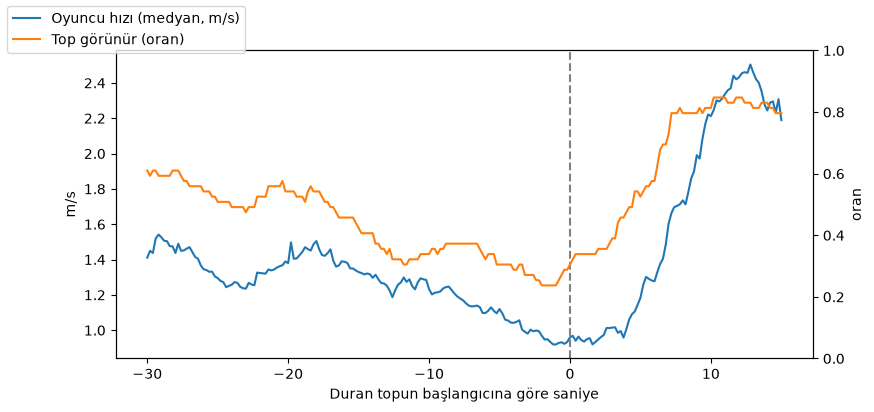

In [7]:
from kloppy import sportscode
import matplotlib.pyplot as plt

st = sportscode.load(paths["smart_tagging"]).to_df()
sp = st[st["code"].str.upper() == "SET PIECES"].copy()
sp["frame"] = (sp["timestamp"].dt.total_seconds() * 25).round().astype(int)
print("Duran top sayısı:", len(sp))
print(sp["Type"].value_counts().to_dict())

offs = np.arange(-30 * 25, 15 * 25 + 1, 5)          # -30 sn .. +15 sn, 5 karede bir
idx = np.clip(sp["frame"].to_numpy()[:, None] + offs[None, :], 0, len(df) - 1)
V = v_smooth[idx]
B = ball_vis[idx]

t = offs / 25
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(t, np.nanmedian(V, axis=0), label="Oyuncu hızı (medyan, m/s)")
ax1.set_xlabel("Duran topun başlangıcına göre saniye")
ax1.set_ylabel("m/s")
ax2 = ax1.twinx()
ax2.plot(t, B.mean(axis=0), color="tab:orange", label="Top görünür (oran)")
ax2.set_ylim(0, 1)
ax2.set_ylabel("oran")
ax1.axvline(0, color="gray", ls="--")
fig.legend(loc="upper left")
plt.show()

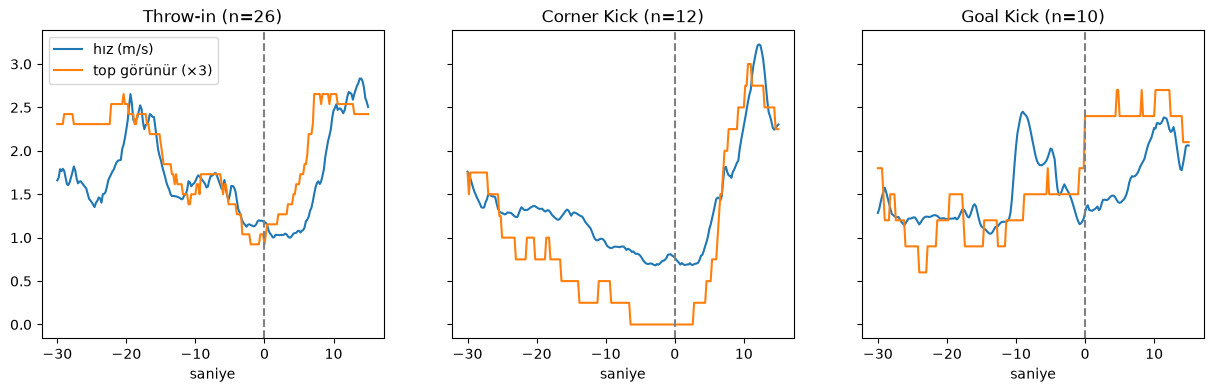

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, tip in zip(axes, ["Throw-in", "Corner Kick", "Goal Kick"]):
    fr = sp.loc[sp["Type"] == tip, "frame"].to_numpy()
    idx_t = np.clip(fr[:, None] + offs[None, :], 0, len(df) - 1)
    ax.plot(t, np.nanmedian(v_smooth[idx_t], axis=0), label="hız (m/s)")
    ax.plot(t, ball_vis[idx_t].mean(axis=0) * 3, label="top görünür (×3)", color="tab:orange")
    ax.axvline(0, color="gray", ls="--")
    ax.set_title(f"{tip} (n={len(fr)})")
    ax.set_xlabel("saniye")
axes[0].legend()
plt.show()

In [9]:
for f in sp.loc[sp["Type"] == "Throw-in", "frame"].head(3):
    s = f / 25
    print(f"video zamanı {int(s // 3600)}:{int(s % 3600 // 60):02d}:{s % 60:05.2f}")

video zamanı 1:16:34.08
video zamanı 0:16:56.40
video zamanı 1:50:55.64


In [10]:
sp["end_frame"] = (sp["end_timestamp"].dt.total_seconds() * 25).round().astype(int)
sp["sure_sn"] = (sp["end_frame"] - sp["frame"]) / 25
print("Duran top aralıklarının süresi (sn):")
print(sp.groupby("Type")["sure_sn"].describe()[["count", "min", "50%", "max"]].round(1))

def vz(f):
    s = f / 25
    return f"{int(s // 3600)}:{int(s % 3600 // 60):02d}:{s % 60:05.2f}"

print("\nİzlediğin üç taç atışı: başlangıç -> bitiş")
for f, e in sp.loc[sp["Type"] == "Throw-in", ["frame", "end_frame"]].head(3).to_numpy():
    print(vz(f), "->", vz(e))

Duran top aralıklarının süresi (sn):
                       count   min   50%   max
Type                                          
Corner Kick             12.0  35.0  35.0  35.0
Free Kick                5.0  35.0  35.0  35.0
Goal Kick               10.0  35.0  35.0  35.0
Kick Off (After Goal)    4.0   5.0   5.0   5.0
Kick Off (Start)         2.0   5.0   5.0   5.0
Throw-in                26.0  35.0  35.0  35.0

İzlediğin üç taç atışı: başlangıç -> bitiş
1:16:34.08 -> 1:17:09.08
0:16:56.40 -> 0:17:31.40
1:50:55.64 -> 1:51:30.64


Topun hızı (m/s), top görünürken:
count    93809.0
mean         6.7
std          6.5
min          0.0
10%          1.0
25%          2.4
50%          5.1
75%          9.5
90%         14.3
99%         24.6
max        431.1
dtype: float64
40 m/s üzeri (fiziksel olarak şüpheli) oranı: 0.0024


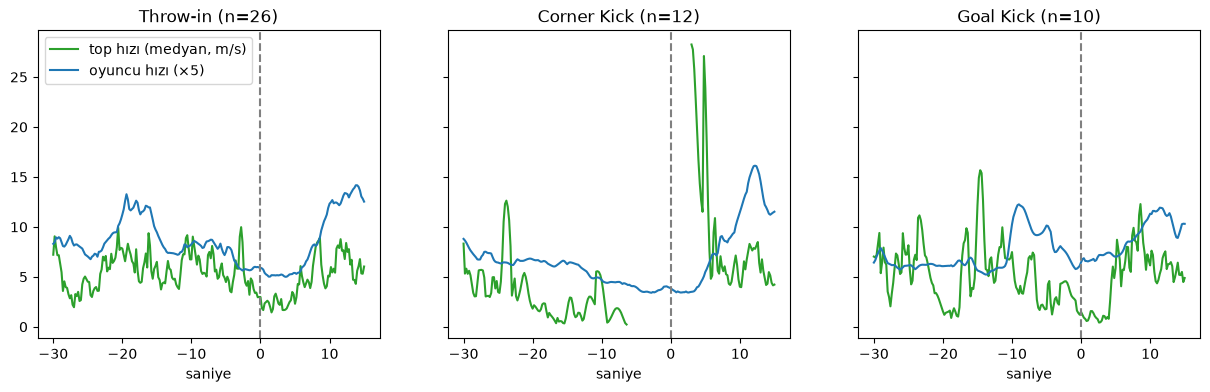

In [11]:
# Sinyal 3: topun hızı (m/s). En fazla 0,2 sn'lik boşlukları doldurup 0,2 sn'lik farkla hesapla
bxs = pd.Series(bx).interpolate(limit=5, limit_area="inside")
bys = pd.Series(by).interpolate(limit=5, limit_area="inside")
v_ball = (np.hypot(bxs.diff(5), bys.diff(5)) / 0.2).rolling(5, center=True, min_periods=1).median().to_numpy()

vb = pd.Series(v_ball[graded & ball_vis])
print("Topun hızı (m/s), top görünürken:")
print(vb.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))
print("40 m/s üzeri (fiziksel olarak şüpheli) oranı:", round((vb > 40).mean(), 4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, tip in zip(axes, ["Throw-in", "Corner Kick", "Goal Kick"]):
    fr = sp.loc[sp["Type"] == tip, "frame"].to_numpy()
    idx_t = np.clip(fr[:, None] + offs[None, :], 0, len(df) - 1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        ax.plot(t, np.nanmedian(v_ball[idx_t], axis=0), label="top hızı (medyan, m/s)", color="tab:green")
    ax.plot(t, np.nanmedian(v_smooth[idx_t], axis=0) * 5, label="oyuncu hızı (×5)", color="tab:blue")
    ax.axvline(0, color="gray", ls="--")
    ax.set_title(f"{tip} (n={len(fr)})")
    ax.set_xlabel("saniye")
axes[0].legend()
plt.show()

In [12]:
# --- Ölü top dedektörü v1 ---
V_BALL_STILL = 2.5     # m/s: altı "top duruyor" (tespit titremesi ~1–2 m/s)
V_BALL_MOVE = 6.0      # m/s: üstü "top oyunda hareket ediyor"
V_PLAYERS_SLOW = 1.3   # m/s: oyuncuların toplu olarak yavaş olduğu eşik
MIN_DEAD = 3 * 25      # en az 3 sn süren durgunluk

def runs_of(mask):
    """True dizisindeki kesintisiz parçalar: (başlangıç, bitiş) çiftleri, bitiş dahil."""
    m = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return list(zip(np.where(m == 1)[0], np.where(m == -1)[0] - 1))

v_ball_c = np.where(v_ball > 40, np.nan, v_ball)            # fiziksel olmayan sıçramaları at
vb0 = np.nan_to_num(v_ball_c, nan=0.0)
ball_still = ball_vis & (vb0 < V_BALL_STILL)
moving = ball_vis & (vb0 > V_BALL_MOVE)
players_slow = v_smooth < V_PLAYERS_SLOW

# 1) Tracking'den ölü top kanıtı, 1 sn'lik pencerede yumuşatılmış
evidence = ball_out | ((~ball_vis | ball_still) & players_slow)
ev_s = pd.Series(evidence.astype(float)).rolling(25, center=True, min_periods=1).mean().to_numpy() > 0.6

dead = np.zeros(len(df), dtype=bool)
for a, b in runs_of(ev_s):
    if b - a + 1 >= MIN_DEAD:
        dead[a:b + 1] = True

# 2) Smart Tagging çapaları: etiketten 3 sn önce -> topun yeniden hareket ettiği ilk an (en fazla 40 sn)
for f in sp["frame"].to_numpy():
    lo, hi = f + 25, min(f + 40 * 25, len(df) - 1)
    nxt = np.argmax(moving[lo:hi]) if moving[lo:hi].any() else hi - lo
    dead[max(f - 3 * 25, 0): lo + nxt] = True

# Özet (puanlanan kareler)
segs = runs_of(dead & graded)
dur = np.array([(b - a + 1) / 25 for a, b in segs])
print("D oranı (puanlanan):", round(dead[graded].mean(), 3))
print("Ölü top dönemi sayısı:", len(segs), "| medyan süre:", round(np.median(dur), 1), "sn",
      "| toplam:", round(dur.sum() / 60, 1), "dk")
print("Kalan oyun süresi:", round((~dead[graded]).sum() / 25 / 60, 1), "dk")
print("Duran topların +2 sn'sinde D olan oran:",
      round(dead[np.clip(sp["frame"].to_numpy() + 50, 0, len(df) - 1)].mean(), 3))
print("D karelerinde top hızlı hareket ediyor oranı:", round(moving[dead & graded].mean(), 3))

D oranı (puanlanan): 0.347
Ölü top dönemi sayısı: 153 | medyan süre: 8.4 sn | toplam: 36.7 dk
Kalan oyun süresi: 69.2 dk
Duran topların +2 sn'sinde D olan oran: 0.949
D karelerinde top hızlı hareket ediyor oranı: 0.013


In [13]:
# --- v2: ölü top + yapışkan sahiplik (her canlı dönem ayrı hesaplanır) ---
pred2 = np.full(len(df), "X", dtype=object)
for _, a, b in half_video_blocks("BAR-ATH"):
    half = np.full(b - a + 1, "D", dtype=object)
    for s, e in runs_of(~dead[a:b + 1]):                      # her canlı dönem
        lab = pd.Series(sticky_confirmed(cand[a + s:a + e + 1], K)).bfill()
        half[s:e + 1] = lab.fillna("X").to_numpy()            # kontrol yoksa çekimser
    pred2[a:b + 1] = half

out2 = ROOT / "evaluation" / "results" / f"v2_dead_R{int(R*10)}_K{K}.csv"
pd.DataFrame({"frame": np.arange(len(df)), "label": pred2}).to_csv(out2, index=False)

p2 = pd.Series(pred2[graded])
degisim = p2[p2 != p2.shift()]
print("Yazıldı:", out2.name)
print("Etiket dağılımı:", p2.value_counts(normalize=True).round(3).to_dict())
print("Sahiplik sayısı:", degisim.isin(["H", "A"]).sum(), "| ölü top dönemi:", (degisim == "D").sum())

Yazıldı: v2_dead_R15_K10.csv
Etiket dağılımı: {np.str_('H'): 0.371, 'D': 0.347, np.str_('A'): 0.254, 'X': 0.028}
Sahiplik sayısı: 349 | ölü top dönemi: 153
